<a href="https://colab.research.google.com/github/studiousdoston/deep-learning-from-scratch-stable-diffusion/blob/main/DiffEdit(paper_replicating).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install -q diffusers transformers accelerate

import torch
from diffusers import AutoencoderKL, UNet2DConditionModel, DDIMScheduler
from transformers import CLIPTextModel, CLIPTokenizer
from PIL import Image, ImageOps
import torchvision.transforms as tfms
import matplotlib.pyplot as plt

device = "cuda"
torch.cuda.is_available()

True

In [ ]:
model_id = "CompVis/stable-diffusion-v1-4"

vae = AutoencoderKL.from_pretrained(model_id, subfolder="vae", torch_dtype=torch.float16).to(device)
unet = UNet2DConditionModel.from_pretrained(model_id, subfolder="unet", torch_dtype=torch.float16).to(device)
tokenizer = CLIPTokenizer.from_pretrained("openai/clip-vit-large-patch14")
text_encoder = CLIPTextModel.from_pretrained("openai/clip-vit-large-patch14", torch_dtype=torch.float16).to(device)
scheduler = DDIMScheduler(beta_start=0.00085, beta_end=0.012, beta_schedule="scaled_linear",
                          clip_sample=False, set_alpha_to_one=False)

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_validators.py:206: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(


config.json:   0%|          | 0.00/551 [00:00<?, ?B/s]

vae/diffusion_pytorch_model.safetensors: reconstructing file:   0%|          |  0.00B /  335MB            

vae/diffusion_pytorch_model.safetensors: downloading bytes:           |  0.00B            

config.json:   0%|          | 0.00/743 [00:00<?, ?B/s]

unet/diffusion_pytorch_model.safetensors: reconstructing file:   0%|          |  0.00B / 3.44GB            

... (7 outputs left out)

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.71GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

[transformers] CLIPTextModel LOAD REPORT from: openai/clip-vit-large-patch14
Key                                                            | Status     |  | 
---------------------------------------------------------------+------------+--+-
vision_model.encoder.layers.{0...23}.self_attn.out_proj.weight | UNEXPECTED |  | 
vision_model.encoder.layers.{0...23}.self_attn.out_proj.bias   | UNEXPECTED |  | 
vision_model.encoder.layers.{0...23}.layer_norm2.bias          | UNEXPECTED |  | 
vision_model.encoder.layers.{0...23}.mlp.fc2.weight            | UNEXPECTED |  | 
vision_model.encoder.layers.{0...23}.self_attn.k_proj.bias     | UNEXPECTED |  | 
vision_model.encoder.layers.{0...23}.layer_norm1.bias          | UNEXPECTED |  | 
vision_model.encoder.layers.{0...23}.mlp.fc1.weight            | UNEXPECTED |  | 
vision_model.pre_layrnorm.weight                               | UNEXPECTED |  | 
vision_model.encoder.layers.{0...23}.self_attn.q_proj.bias     | UNEXPECTED |  | 
vision_model.encoder.

In [ ]:
def text_embed(prompts):
  tokens = tokenizer(prompts, padding="max_length", max_length=tokenizer.model_max_length,
                     truncation=True, return_tensors="pt")
  with torch.no_grad():
    return text_encoder(tokens.input_ids.to(device))[0]
# Prompt text → CLIP embeddings [n, 77, 768]

def pil_to_latent(img):
  x = tfms.ToTensor()(img).unsqueeze(0).to(device, torch.float16)*2-1
  with torch.no_grad():
    return vae.encode(x).latent_dist.sample()*0.18215
# Image → latent [1, 4, 64, 64]

def latents_to_pil(latents):
  with torch.no_grad():
    img = vae.decode(latents / 0.18215).sample
  img = (img / 2 + 0.5).clamp(0, 1).permute(0, 2, 3, 1).float().cpu().numpy()
  return [Image.fromarray((i * 255).round().astype("uint8"))for i in img]
# Latent -> images


Saving tea.jpeg to tea.jpeg


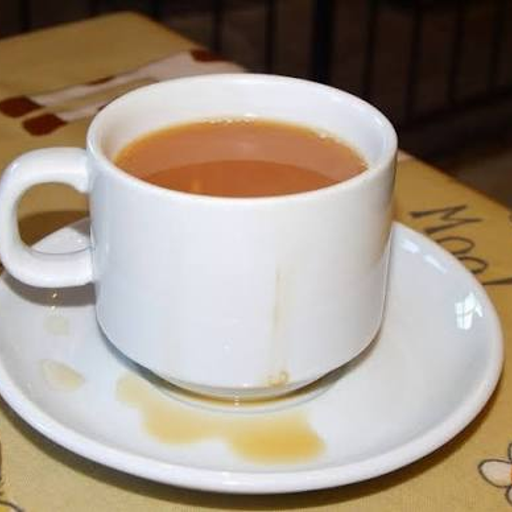

In [212]:
from google.colab import files
uploaded  = files.upload()
fname = next(iter(uploaded))
init_image = ImageOps.fit(Image.open(fname).convert('RGB'), (512, 512))
init_image

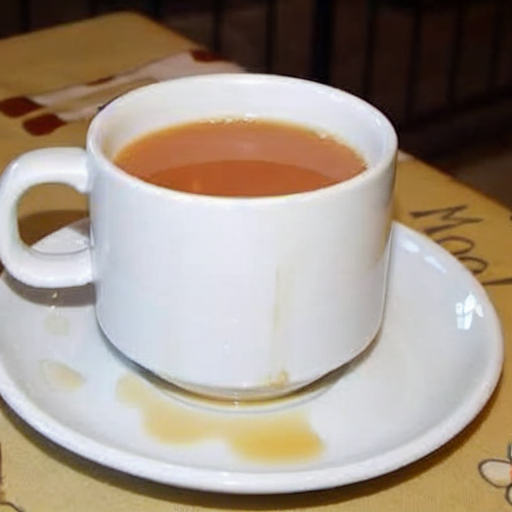

In [213]:
latents_to_pil(pil_to_latent(init_image))[0]

In [215]:
ref_prompt = "a cup of tea on a saucer"
target_prompt = "a cup of hot chocolate on a saucer"

In [218]:
scheduler.set_timesteps(50)
latent = pil_to_latent(init_image)
t = scheduler.timesteps[len(scheduler.timesteps) // 2]

ref_emb = text_embed([ref_prompt])
tgt_emb = text_embed([target_prompt])

diffs = []

for _ in range(10):
  noise = torch.randn_like(latent)
  noisy = scheduler.add_noise(latent, noise, t)

  with torch.no_grad():
    eps_ref = unet(noisy, t, encoder_hidden_states=ref_emb).sample
    eps_tgt = unet(noisy, t, encoder_hidden_states=tgt_emb).sample

    diffs.append((eps_tgt-eps_ref).abs())


In [219]:
diff = torch.stack(diffs).mean(0).mean(1)[0].float()

diff = (diff - diff.min()) / (diff.max() - diff.min())

mask = (diff > 0.5).float()
mask = F.max_pool2d(mask[None, None], kernel_size=11, stride=1, padding=5)[0, 0]


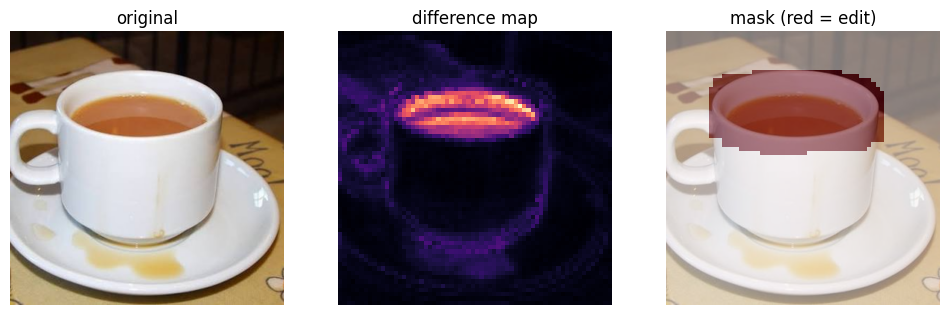

In [220]:
fig, axs = plt.subplots(1, 3, figsize=(12, 4))
axs[0].imshow(init_image);  axs[0].set_title("original")
axs[1].imshow(diff.cpu(), cmap="magma");  axs[1].set_title("difference map")
axs[2].imshow(init_image)
axs[2].imshow(mask.cpu(), alpha=0.5, cmap="Reds", extent=(0, 512, 512, 0))
axs[2].set_title("mask (red = edit)")
for a in axs: a.axis("off")
plt.show()

In [221]:
strength = 0.7
guidance = 5

scheduler.set_timesteps(50)
start = int(50 * (1 - strength))
timesteps = scheduler.timesteps[start:]

orig = pil_to_latent(init_image)
noise = torch.randn_like(orig)
latents = scheduler.add_noise(orig, noise, timesteps[0])

emb = torch.cat([text_embed([""]), text_embed([target_prompt])])
m = mask.to(device, torch.float16)[None, None]

for i, t in enumerate(timesteps):
    with torch.no_grad():
        eps = unet(torch.cat([latents] * 2), t, encoder_hidden_states=emb).sample
    eps_uncond, eps_text = eps.chunk(2)
    eps = eps_uncond + guidance * (eps_text - eps_uncond)

    latents = scheduler.step(eps, t, latents).prev_sample

    if i < len(timesteps) - 1:
        bg = scheduler.add_noise(orig, noise, timesteps[i + 1])
    else:
        bg = orig

    latents = m * latents + (1 - m) * bg

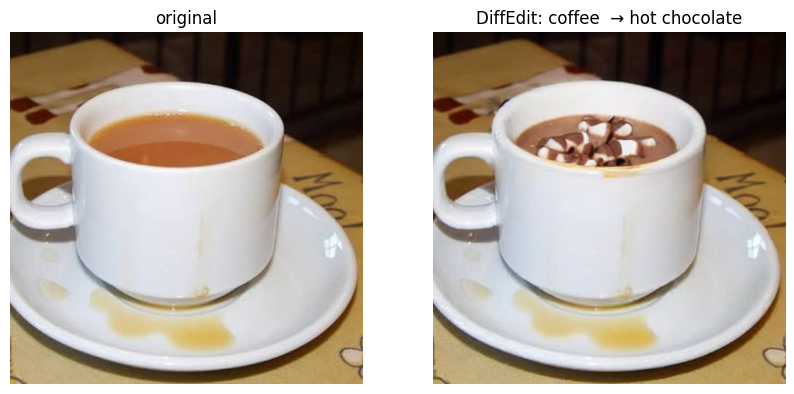

In [227]:
result = latents_to_pil(latents)[0]
fig, axs = plt.subplots(1, 2, figsize=(10, 5))
axs[0].imshow(init_image); axs[0].set_title("original")
axs[1].imshow(result);     axs[1].set_title("DiffEdit: coffee  → hot chocolate")
for a in axs: a.axis("off")
plt.show()

## Prompt 2

In [ ]:
# ===== DiffEdit: upload a photo, write 2 prompts, get the mask + edited image =====
import torch, torch.nn.functional as F
import matplotlib.pyplot as plt
import torchvision.transforms as tfms
from PIL import Image, ImageOps
from google.colab import files
from scipy.ndimage import binary_fill_holes
from diffusers import AutoencoderKL, UNet2DConditionModel, DDIMScheduler
from transformers import CLIPTextModel, CLIPTokenizer

device = "cuda"
if 'unet' not in globals():
    mid = "CompVis/stable-diffusion-v1-4"
    vae = AutoencoderKL.from_pretrained(mid, subfolder="vae", torch_dtype=torch.float16).to(device)
    unet = UNet2DConditionModel.from_pretrained(mid, subfolder="unet", torch_dtype=torch.float16).to(device)
    tokenizer = CLIPTokenizer.from_pretrained("openai/clip-vit-large-patch14")
    text_encoder = CLIPTextModel.from_pretrained("openai/clip-vit-large-patch14", torch_dtype=torch.float16).to(device)
scheduler = DDIMScheduler(beta_start=0.00085, beta_end=0.012, beta_schedule="scaled_linear",
                          clip_sample=False, set_alpha_to_one=False)
# Load the models only if they aren't loaded yet (re-running the cell stays fast)


def text_embed(prompts):
    tok = tokenizer(prompts, padding="max_length", max_length=tokenizer.model_max_length,
                    truncation=True, return_tensors="pt")
    with torch.no_grad():
        return text_encoder(tok.input_ids.to(device))[0]

def pil_to_latent(img):
    x = tfms.ToTensor()(img).unsqueeze(0).to(device, torch.float16) * 2 - 1
    with torch.no_grad():
        return vae.encode(x).latent_dist.sample() * 0.18215

def latents_to_pil(lat):
    with torch.no_grad():
        img = vae.decode(lat / 0.18215).sample
    img = (img / 2 + 0.5).clamp(0, 1).permute(0, 2, 3, 1).float().cpu().numpy()
    return [Image.fromarray((i * 255).round().astype("uint8")) for i in img]
# Helpers: prompt → embeddings, image → latent, latent → image


def diffedit(ref_prompt, target_prompt, image=None, threshold=0.3, dilate=9,
             strength=0.7, guidance=7.5, n_noise=10, seed=42):
    if image is None:
        up = files.upload()
        image = ImageOps.fit(Image.open(next(iter(up))).convert("RGB"), (512, 512))
    torch.manual_seed(seed)
    scheduler.set_timesteps(50)
    latent = pil_to_latent(image)
    ref_emb, tgt_emb = text_embed([ref_prompt]), text_embed([target_prompt])
    # Upload (if no image given), crop to 512×512, encode, embed both prompts

    # ---- Paper step 1: the mask ----
    t_mask = scheduler.timesteps[len(scheduler.timesteps) // 2]
    diff = torch.zeros(64, 64, device=device)
    for _ in range(n_noise):
        noisy = scheduler.add_noise(latent, torch.randn_like(latent), t_mask)
        with torch.no_grad():
            e_ref = unet(noisy, t_mask, encoder_hidden_states=ref_emb).sample
            e_tgt = unet(noisy, t_mask, encoder_hidden_states=tgt_emb).sample
        diff += (e_tgt - e_ref).abs().mean(1)[0].float()
    diff /= n_noise
    diff = (diff - diff.min()) / (diff.max() - diff.min() + 1e-8)
    # Average difference between the two predictions, rescaled to 0–1

    diff = F.avg_pool2d(diff[None, None], 5, stride=1, padding=2)[0, 0]
    # Blur slightly: random specks fade, real areas stay bright

    mask = (diff > threshold).float()
    if dilate > 1:
        mask = F.max_pool2d(mask[None, None], dilate, stride=1, padding=dilate // 2)[0, 0]
    # Threshold, then grow the mask

    mask = torch.tensor(binary_fill_holes(mask.cpu().numpy()), device=device).float()
    # Fill holes: anything fully surrounded by mask becomes mask (ring → solid shape)

    # ---- Paper steps 2 + 3: masked denoising ----
    timesteps = scheduler.timesteps[int(50 * (1 - strength)):]
    noise = torch.randn_like(latent)
    latents = scheduler.add_noise(latent, noise, timesteps[0])
    emb = torch.cat([ref_emb, tgt_emb])
    m = mask.to(device, torch.float16)[None, None]
    for i, t in enumerate(timesteps):
        with torch.no_grad():
            eps = unet(torch.cat([latents] * 2), t, encoder_hidden_states=emb).sample
        e_ref, e_tgt = eps.chunk(2)
        eps = e_ref + guidance * (e_tgt - e_ref)
        latents = scheduler.step(eps, t, latents).prev_sample
        bg = scheduler.add_noise(latent, noise, timesteps[i + 1]) if i < len(timesteps) - 1 else latent
        latents = m * latents + (1 - m) * bg
    # Each step: guided noise prediction (away from ref, toward target), remove some noise,
    # paste the original back OUTSIDE the mask

    result = latents_to_pil(latents)[0]
    fig, axs = plt.subplots(1, 4, figsize=(18, 4.5))
    axs[0].imshow(image);                         axs[0].set_title("original")
    axs[1].imshow(diff.cpu(), cmap="magma");      axs[1].set_title("difference map")
    axs[2].imshow(image)
    axs[2].imshow(mask.cpu(), alpha=0.5, cmap="Reds", extent=(0, 512, 512, 0))
    axs[2].set_title(f"mask (threshold {threshold}, dilate {dilate})")
    axs[3].imshow(result);                        axs[3].set_title(f"edited (strength {strength})")
    for a in axs: a.axis("off")
    plt.show()
    return image, mask, result



Saving person.jpeg to person (7).jpeg


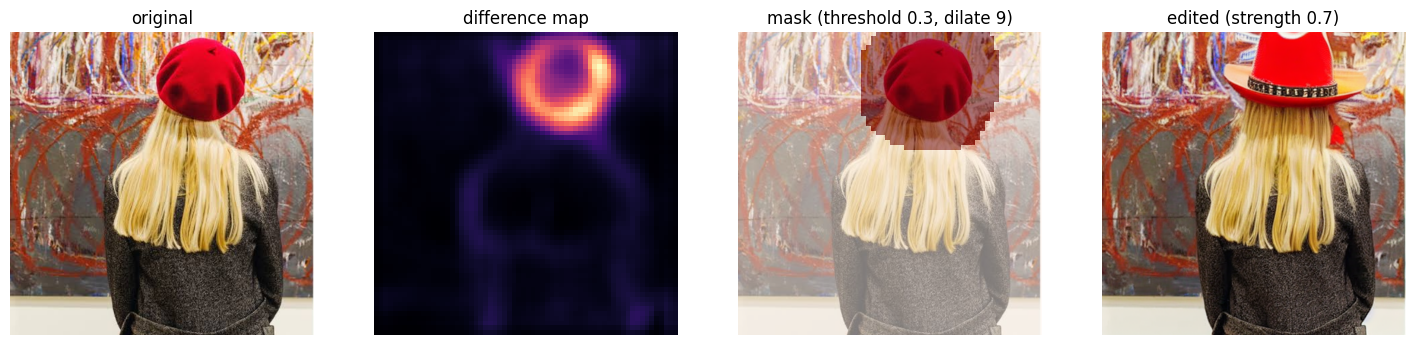

In [ ]:
# ===== Run it =====
img, mask, out = diffedit("a woman wearing a beret", "a woman wearing a cowboy hat")

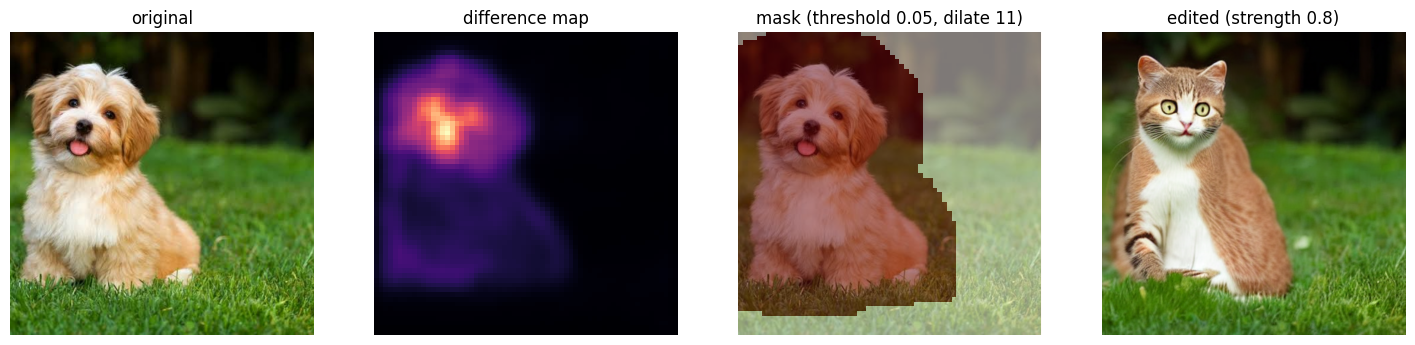

In [ ]:
img, mask, out = diffedit("a dog sitting on the grass", "a cat sitting on the grass",
                          image=img, threshold=0.05, dilate=11, strength=0.8)

### Reference: Hugging Face DiffEdit

/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

The StableDiffusionDiffEditPipeline has been deprecated and will not receive bug fixes or feature updates after Diffusers version 0.33.1. 
You have disabled the safety checker for <class 'diffusers.pipelines.deprecated.stable_diffusion_diffedit.pipeline_stable_diffusion_diffedit.StableDiffusionDiffEditPipeline'> by passing `safety_checker=None`. Ensure that you abide to the conditions of the Stable Diffusion license and do not expose unfiltered results in services or applications open to the public. Both the diffusers team and Hugging Face strongly recommend to keep the safety filter enabled in all public facing circumstances, disabling it only for use-cases that involve analyzing network behavior or auditing its results. For more information, please have a look at https://github.com/huggingface/diffusers/pull/254 .
The config attributes {'skip_prk_steps': True} were passed to DDIMInverseScheduler, but are not expected and will be ignored. Please verify your scheduler_config.json confi

  0%|          | 0/40 [00:00<?, ?it/s]

  0%|          | 0/40 [00:00<?, ?it/s]

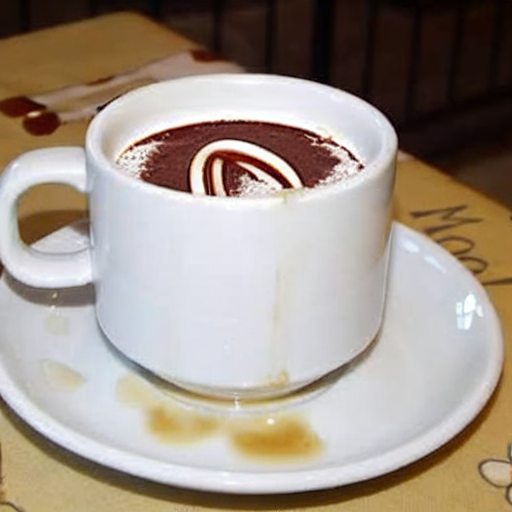

In [226]:
from diffusers import StableDiffusionDiffEditPipeline, DDIMScheduler, DDIMInverseScheduler

ref = StableDiffusionDiffEditPipeline.from_pretrained(
    "CompVis/stable-diffusion-v1-4", torch_dtype=torch.float16, safety_checker=None).to(device)
ref.scheduler = DDIMScheduler.from_config(ref.scheduler.config)
ref.inverse_scheduler = DDIMInverseScheduler.from_config(ref.scheduler.config)

mask_img = ref.generate_mask(image=init_image, source_prompt=ref_prompt, target_prompt=target_prompt)

inv_latents = ref.invert(image=init_image, prompt=ref_prompt).latents

out = ref(prompt=target_prompt, mask_image=mask_img, image_latents=inv_latents,
          negative_prompt=ref_prompt).images[0]

out